# Makine Öğrenmesi ile Ağ Saldırısı Tespiti (IDS) — NSL-KDD

Bu notebook'ta ağ bağlantılarının trafik özelliklerinden yola çıkarak bir bağlantının **normal** mi yoksa **saldırı** mı olduğunu ve saldırıysa hangi kategoriye (DoS, Probe, R2L, U2R) ait olduğunu tahmin eden modeller geliştirilmektedir.

**İçerik**
1. Kurulum ve veri yükleme
2. Veri keşfi (EDA)
3. Ön işleme
4. Model eğitimi ve hiperparametre ayarı (Logistic Regression, Random Forest, XGBoost)
5. Sınıf dengesizliği: `class_weight` ve SMOTE karşılaştırması
6. Test kümesinde değerlendirme (5 sınıflı ve ikili)
7. Hata analizi
8. Autoencoder ile anomali tespiti
9. Tüm yöntemlerin ikili karşılaştırması

**Veri seti:** NSL-KDD — Tavallaee, M., Bagheri, E., Lu, W., Ghorbani, A. (2009). *A Detailed Analysis of the KDD CUP 99 Data Set.* Canadian Institute for Cybersecurity, University of New Brunswick — https://www.unb.ca/cic/datasets/nsl.html

In [1]:
import json, time, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR, FIG_DIR, RES_DIR = ROOT / 'data', ROOT / 'figures', ROOT / 'results'
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    d.mkdir(exist_ok=True)

# --- Grafik stili: tüm şekillerde aynı renkler aynı anlamı taşır ---
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
CLASSES = ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']
CLASS_COLORS = dict(zip(CLASSES, PALETTE))
MODELS = ['Logistic Regression', 'Random Forest', 'XGBoost']
MODEL_COLORS = {'Logistic Regression': PALETTE[0], 'Random Forest': PALETTE[1], 'XGBoost': PALETTE[2],
                'Autoencoder': PALETTE[3], 'Hibrit': PALETTE[6]}
SPLIT_COLORS = ['#86b6ef', '#184f95']          # eğitim / test
SEQ_CMAP = LinearSegmentedColormap.from_list('seq', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
DIV_CMAP = LinearSegmentedColormap.from_list('div', ['#104281', '#5598e7', '#f0efec', '#ec835a', '#b8322f'])

# Segoe UI Windows yazı tipidir; Colab/Linux'ta yoksa DejaVu Sans kullanılır (uyarı çıkmaz)
from matplotlib import font_manager
FONT = 'Segoe UI' if 'Segoe UI' in {f.name for f in font_manager.fontManager.ttflist} else 'DejaVu Sans'
TITLE_W = 'semibold' if FONT == 'Segoe UI' else 'bold'   # DejaVu Sans'ta semibold yok

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.grid': True, 'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': FONT, 'font.size': 10, 'axes.titlesize': 11.5, 'axes.titleweight': TITLE_W,
    'legend.frameon': False, 'figure.dpi': 100, 'savefig.dpi': 160, 'savefig.bbox': 'tight', 'lines.linewidth': 2,
})

def finish(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')
    plt.show()

def tr_int(v):
    return f'{v:,.0f}'.replace(',', '.')

print('Proje klasörü:', ROOT)

Proje klasörü: C:\Users\bzkr_\OneDrive\Masaüstü\Staj\ML IDS


## 1. Veri setinin yüklenmesi

NSL-KDD iki dosyadan oluşur: `KDDTrain+.txt` (eğitim) ve `KDDTest+.txt` (test). Dosyalarda başlık satırı yoktur; sütun adları veri setinin dokümantasyonuna göre aşağıda tanımlanmıştır. Her satırda 41 özellik, saldırı adı (`label`) ve kaydın zorluk derecesi (`difficulty`) bulunur.

Dosyalar `data/` klasöründe yoksa otomatik olarak indirilir.

In [2]:
FEATURE_COLUMNS = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent',
    'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root',
    'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login',
    'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
    'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
    'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']
COLUMNS = FEATURE_COLUMNS + ['label', 'difficulty']
assert len(FEATURE_COLUMNS) == 41

BASE_URL = 'https://raw.githubusercontent.com/defcom17/NSL_KDD/master/'
for fname in ['KDDTrain+.txt', 'KDDTest+.txt']:
    path = DATA_DIR / fname
    if not path.exists():
        print('İndiriliyor:', fname)
        urllib.request.urlretrieve(BASE_URL + fname.replace('+', '%2B'), path)

train_raw = pd.read_csv(DATA_DIR / 'KDDTrain+.txt', header=None, names=COLUMNS)
test_raw = pd.read_csv(DATA_DIR / 'KDDTest+.txt', header=None, names=COLUMNS)
print('Eğitim:', train_raw.shape, '| Test:', test_raw.shape)
train_raw.head()

Eğitim: (125973, 43) | Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


### Saldırı adlarının kategorilere eşlenmesi

`label` sütununda tek tek saldırı adları (ör. `neptune`, `smurf`, `guess_passwd`) bulunur. Bunlar literatürde kullanılan standart eşlemeyle dört ana kategoriye toplanır:

| Kategori | Açıklama |
|---|---|
| **DoS** | Hizmeti kullanılamaz hâle getirme (ör. SYN flood) |
| **Probe** | Keşif / tarama (ör. port taraması) |
| **R2L** | Uzaktan yetkisiz erişim (ör. parola deneme) |
| **U2R** | Normal kullanıcıdan root yetkisine yükselme (ör. buffer overflow) |

In [3]:
ATTACK_GROUPS = {
    'DoS':   ['back', 'land', 'neptune', 'pod', 'smurf', 'teardrop', 'apache2', 'mailbomb', 'processtable', 'udpstorm'],
    'Probe': ['ipsweep', 'nmap', 'portsweep', 'satan', 'mscan', 'saint'],
    'R2L':   ['ftp_write', 'guess_passwd', 'imap', 'multihop', 'phf', 'spy', 'warezclient', 'warezmaster', 'named',
              'sendmail', 'snmpgetattack', 'snmpguess', 'worm', 'xlock', 'xsnoop'],
    'U2R':   ['buffer_overflow', 'loadmodule', 'perl', 'rootkit', 'httptunnel', 'ps', 'sqlattack', 'xterm'],
}
ATTACK_MAP = {a: g for g, attacks in ATTACK_GROUPS.items() for a in attacks}
ATTACK_MAP['normal'] = 'Normal'

def add_targets(df):
    df = df.copy()
    df['category'] = df['label'].map(ATTACK_MAP)
    unknown = df.loc[df['category'].isna(), 'label'].unique()
    assert len(unknown) == 0, f'Eşlenmemiş etiketler: {unknown}'
    df['is_attack'] = (df['category'] != 'Normal').astype(int)
    return df

train = add_targets(train_raw)
test = add_targets(test_raw)

train_attack_types = set(train['label'].unique())
test['seen_in_train'] = test['label'].isin(train_attack_types)
print('Eğitimdeki farklı etiket sayısı:', train['label'].nunique(), '| Testteki:', test['label'].nunique())

Eğitimdeki farklı etiket sayısı: 23 | Testteki: 38


## 2. Veri keşfi (EDA)

### 2.1 Genel kontroller: veri tipleri, eksik değer, tekrar eden kayıt, sabit sütun

In [4]:
cat_cols = ['protocol_type', 'service', 'flag']
overview = pd.DataFrame({
    'Satır': [len(train), len(test)],
    'Eksik değer': [train[FEATURE_COLUMNS].isna().sum().sum(), test[FEATURE_COLUMNS].isna().sum().sum()],
    'Tekrar eden satır': [train.duplicated(subset=FEATURE_COLUMNS + ['label']).sum(),
                          test.duplicated(subset=FEATURE_COLUMNS + ['label']).sum()],
}, index=['Eğitim', 'Test'])
display(overview)

print('Kategorik sütunlar ve farklı değer sayıları:',
      {c: train[c].nunique() for c in cat_cols})
print('Sayısal sütun sayısı:', len(FEATURE_COLUMNS) - len(cat_cols))
constant = [c for c in FEATURE_COLUMNS if train[c].nunique() == 1]
print('Eğitimde tek değerli (sabit) sütunlar:', constant)
for c in cat_cols:
    unseen_vals = sorted(set(test[c]) - set(train[c]))
    print(f'{c}: testte olup eğitimde olmayan değerler -> {unseen_vals}')

,Satır,Eksik değer,Tekrar eden satır
Eğitim,125973,0,0
Test,22544,0,0


Kategorik sütunlar ve farklı değer sayıları: {'protocol_type': 3, 'service': 70, 'flag': 11}
Sayısal sütun sayısı: 38


Eğitimde tek değerli (sabit) sütunlar: ['num_outbound_cmds']
protocol_type: testte olup eğitimde olmayan değerler -> []
service: testte olup eğitimde olmayan değerler -> []
flag: testte olup eğitimde olmayan değerler -> []


### 2.2 Sınıf dağılımı (eğitim ve test)

,Eğitim (KDDTrain+),Test (KDDTest+),Eğitim %,Test %
category,,,,
Normal,67343,9711,53.46,43.08
DoS,45927,7458,36.46,33.08
Probe,11656,2421,9.25,10.74
R2L,995,2754,0.79,12.22
U2R,52,200,0.04,0.89


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


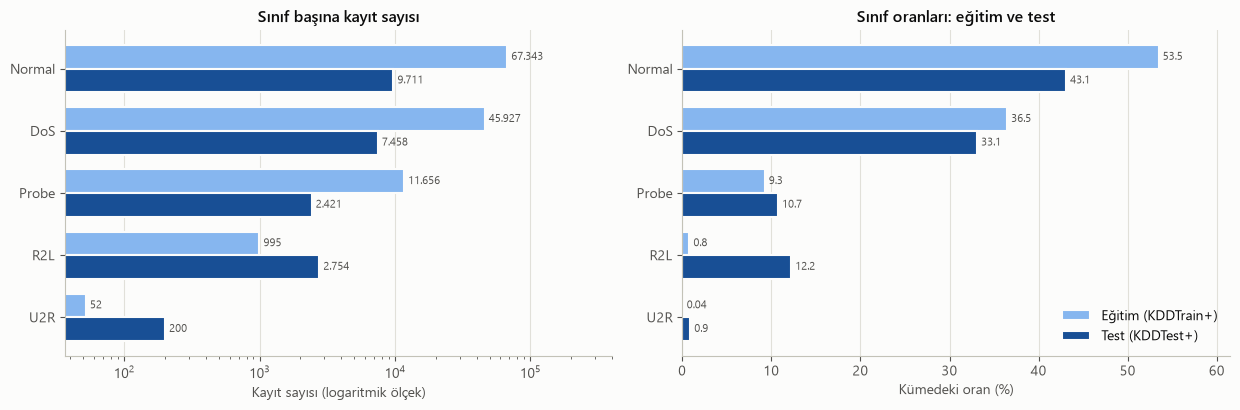

In [5]:
counts = pd.DataFrame({'Eğitim (KDDTrain+)': train['category'].value_counts(),
                       'Test (KDDTest+)': test['category'].value_counts()}).reindex(CLASSES)
pct = counts / counts.sum() * 100
class_table = counts.copy()
class_table['Eğitim %'] = pct.iloc[:, 0].round(2)
class_table['Test %'] = pct.iloc[:, 1].round(2)
display(class_table)
class_table.to_csv(RES_DIR / 'class_distribution.csv')

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
y, h = np.arange(len(CLASSES)), 0.38
for ax, data, xlabel, is_count in [(axes[0], counts, 'Kayıt sayısı (logaritmik ölçek)', True),
                                    (axes[1], pct, 'Kümedeki oran (%)', False)]:
    for i, (col, color) in enumerate(zip(data.columns, SPLIT_COLORS)):
        bars = ax.barh(y + (i - 0.5) * h, data[col], height=h, color=color, edgecolor=SURFACE, linewidth=1.5, label=col)
        ax.bar_label(bars, labels=[tr_int(v) if is_count else (f'{v:.1f}' if v >= 0.1 else f'{v:.2f}') for v in data[col]],
                     padding=3, fontsize=8, color=INK2)
    ax.set_yticks(y, CLASSES)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)
    if is_count:
        ax.set_xscale('log')
        ax.set_xlim(right=counts.values.max() * 6)
    else:
        ax.set_xlim(right=pct.values.max() * 1.15)
axes[0].set_title('Sınıf başına kayıt sayısı')
axes[1].set_title('Sınıf oranları: eğitim ve test')
axes[1].legend(loc='lower right')
fig.tight_layout()
finish(fig, '01_sinif_dagilimi')

**Gözlem:** Veri çok dengesiz: eğitimde U2R yalnızca 52 kayıt (%0.04). Test dağılımı da farklı: R2L eğitimde %0.8, testte %12.2. Bu yüzden accuracy tek başına yanıltıcı olur; macro F1 ve sınıf bazlı recall kullanılacak.

In [6]:
unseen = (test.loc[~test['seen_in_train'] & (test['is_attack'] == 1)]
          .groupby(['category', 'label']).size().rename('Test kayıt sayısı').reset_index()
          .sort_values(['category', 'Test kayıt sayısı'], ascending=[True, False]))
n_attack_test = int(test['is_attack'].sum())
n_unseen = int(unseen['Test kayıt sayısı'].sum())
print(f'Testteki saldırı kayıtları: {n_attack_test} | eğitimde hiç görülmemiş türlerden gelenler: {n_unseen} '
      f'(%{100 * n_unseen / n_attack_test:.1f})')
print('Kategori bazında görülmemiş saldırı oranı (test):')
display((test[test.is_attack == 1].groupby('category')['seen_in_train']
         .apply(lambda s: round(100 * (1 - s.mean()), 1)).rename('% görülmemiş')))
display(unseen.reset_index(drop=True))

Testteki saldırı kayıtları: 12833 | eğitimde hiç görülmemiş türlerden gelenler: 3750 (%29.2)
Kategori bazında görülmemiş saldırı oranı (test):


category
DoS      23.0
Probe    54.3
R2L      20.2
U2R      81.5
Name: % görülmemiş, dtype: float64

,category,label,Test kayıt sayısı
0,DoS,apache2,737
1,DoS,processtable,685
2,DoS,mailbomb,293
3,DoS,udpstorm,2
4,Probe,mscan,996
5,Probe,saint,319
6,R2L,snmpguess,331
7,R2L,snmpgetattack,178
8,R2L,named,17
9,R2L,sendmail,14


**Gözlem:** Testteki saldırıların önemli bir kısmı (%29.2) eğitimde **hiç bulunmayan** saldırı türlerinden geliyor. U2R ve Probe'da bu oran özellikle yüksek. Denetimli modellerin bu kayıtlarda zorlanması beklenir; bu, gerçek hayattaki yeni (zero-day) saldırı senaryosunu temsil eder.

### 2.3 Protokol ve bağlantı durumu (flag) ile sınıf ilişkisi

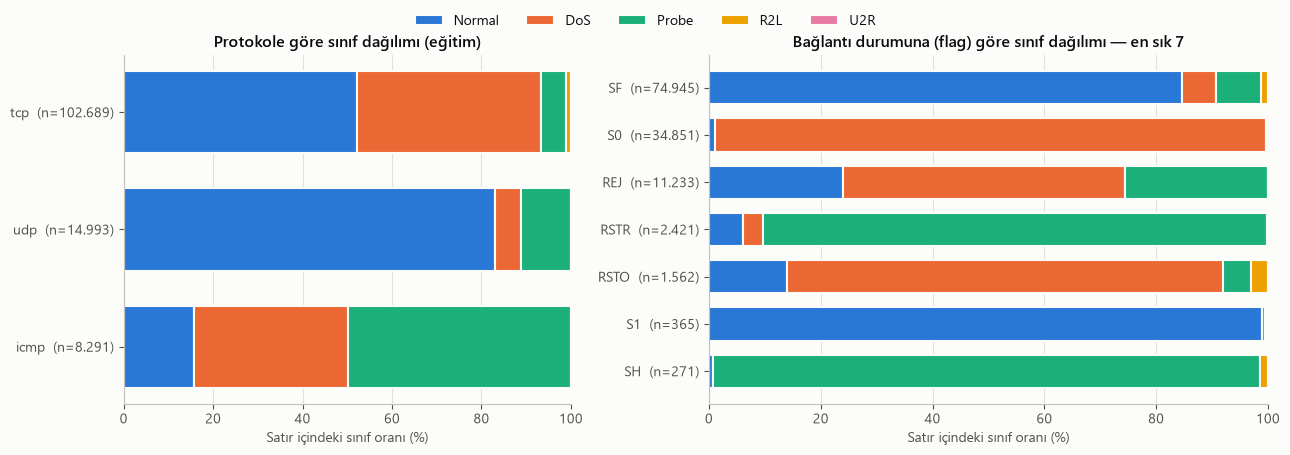

category,Normal,DoS,Probe,R2L,U2R
flag,,,,,
SF,63393,4599,5967,935,51
S0,354,34344,153,0,0
REJ,2693,5671,2869,0,0
RSTR,146,90,2180,5,0
RSTO,219,1216,80,46,1


In [7]:
def stacked_share(ax, col, top=None, title=''):
    n = train[col].value_counts()
    order = n.index[:top] if top else n.index
    ct = (pd.crosstab(train[col], train['category'], normalize='index')
          .reindex(index=order, columns=CLASSES, fill_value=0) * 100)
    left = np.zeros(len(ct))
    ypos = np.arange(len(ct))
    for c in CLASSES:
        ax.barh(ypos, ct[c], left=left, color=CLASS_COLORS[c], edgecolor=SURFACE, linewidth=1.5, label=c, height=0.7)
        left += ct[c].values
    ax.set_yticks(ypos, [f'{i}  (n={tr_int(n[i])})' for i in ct.index])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel('Satır içindeki sınıf oranı (%)')
    ax.set_title(title)
    ax.grid(axis='y', visible=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'width_ratios': [1, 1.25]})
stacked_share(axes[0], 'protocol_type', title='Protokole göre sınıf dağılımı (eğitim)')
stacked_share(axes[1], 'flag', top=7, title='Bağlantı durumuna (flag) göre sınıf dağılımı — en sık 7')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
finish(fig, '02_protokol_flag')

display(pd.crosstab(train['flag'], train['category']).reindex(columns=CLASSES).loc[['SF', 'S0', 'REJ', 'RSTR', 'RSTO']])

**Gözlem:** `flag = S0` (yanıtsız SYN isteği) olan bağlantıların neredeyse tamamı DoS'tur (SYN flood), `RSTR` ve `SH` ise büyük ölçüde Probe'tur (port taraması). ICMP trafiği ağırlıkla Probe ve DoS'a aittir. Bağlantı durumu ve protokol, saldırı türü için güçlü ipuçlarıdır.

### 2.4 Aktarılan byte miktarlarının dağılımı

,Ortalama,Medyan,Maksimum,% sıfır,Çarpıklık (skewness)
duration,287.14,0.0,42908,92.05,11.88
src_bytes,45566.74,44.0,1379963888,39.21,190.67
dst_bytes,19779.11,0.0,1309937401,53.95,290.05


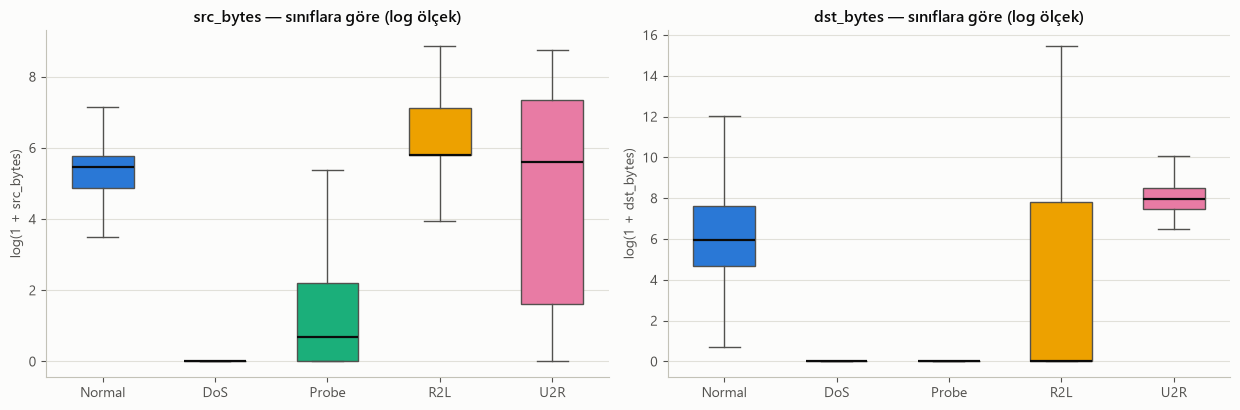

In [8]:
byte_cols = ['duration', 'src_bytes', 'dst_bytes']
display(pd.DataFrame({'Ortalama': train[byte_cols].mean(), 'Medyan': train[byte_cols].median(),
                      'Maksimum': train[byte_cols].max(), '% sıfır': (train[byte_cols] == 0).mean() * 100,
                      'Çarpıklık (skewness)': train[byte_cols].skew()}).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for ax, col in zip(axes, ['src_bytes', 'dst_bytes']):
    data = [np.log1p(train.loc[train['category'] == c, col]) for c in CLASSES]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.55,
                    medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=INK2),
                    capprops=dict(color=INK2))
    for patch, c in zip(bp['boxes'], CLASSES):
        patch.set_facecolor(CLASS_COLORS[c]); patch.set_edgecolor(INK2)
    ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES)
    ax.set_ylabel(f'log(1 + {col})')
    ax.set_title(f'{col} — sınıflara göre (log ölçek)')
    ax.grid(axis='x', visible=False)
fig.tight_layout()
finish(fig, '03_byte_dagilimi')

**Gözlem:** Byte ve süre değerleri aşırı çarpıktır (çok sayıda 0, çok büyük maksimumlar). Log dönüşümü uygulanmazsa özellikle Logistic Regression ve autoencoder bu sütunlardaki birkaç uç değerden aşırı etkilenir.

### 2.5 Zaman tabanlı trafik özellikleri
`count`: son 2 saniyede aynı hedef hosta yapılan bağlantı sayısı · `serror_rate`: bu bağlantılardaki SYN hatası oranı · `same_srv_rate`: aynı servise giden bağlantıların oranı · `dst_host_srv_count`: son 100 bağlantıda aynı servise yapılanların sayısı.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


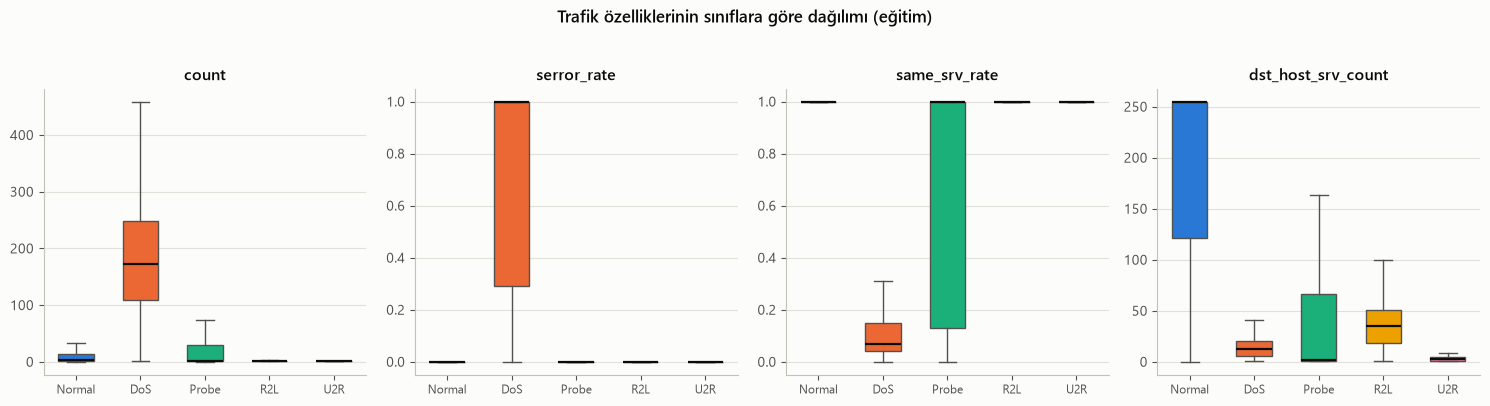

,count,serror_rate,same_srv_rate,dst_host_srv_count
category,,,,
Normal,4.0,0.0,1.00,255.0
DoS,172.0,1.0,0.07,13.0
Probe,1.0,0.0,1.00,2.0
R2L,1.0,0.0,1.00,35.0
U2R,1.0,0.0,1.00,2.5


In [9]:
traffic_cols = ['count', 'serror_rate', 'same_srv_rate', 'dst_host_srv_count']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, col in zip(axes, traffic_cols):
    data = [train.loc[train['category'] == c, col] for c in CLASSES]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.55,
                    medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, c in zip(bp['boxes'], CLASSES):
        patch.set_facecolor(CLASS_COLORS[c]); patch.set_edgecolor(INK2)
    ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES, fontsize=8.5)
    ax.set_title(col)
    ax.grid(axis='x', visible=False)
fig.suptitle('Trafik özelliklerinin sınıflara göre dağılımı (eğitim)', y=1.03, fontweight=TITLE_W)
fig.tight_layout()
finish(fig, '04_trafik_ozellikleri')

display(train.groupby('category')[traffic_cols].median().reindex(CLASSES).round(2))

**Gözlem:** DoS bağlantılarında son 2 saniyedeki bağlantı sayısı (`count`) ve SYN hata oranı (`serror_rate`) çok yüksek; Probe'da aynı servise giden bağlantı oranı düşük. R2L ve U2R ise bu trafik özelliklerinde normal trafikten neredeyse ayırt edilemiyor; bu iki sınıfın zor olacağını şimdiden gösteriyor.

### 2.6 Sayısal özellikler arasındaki korelasyon

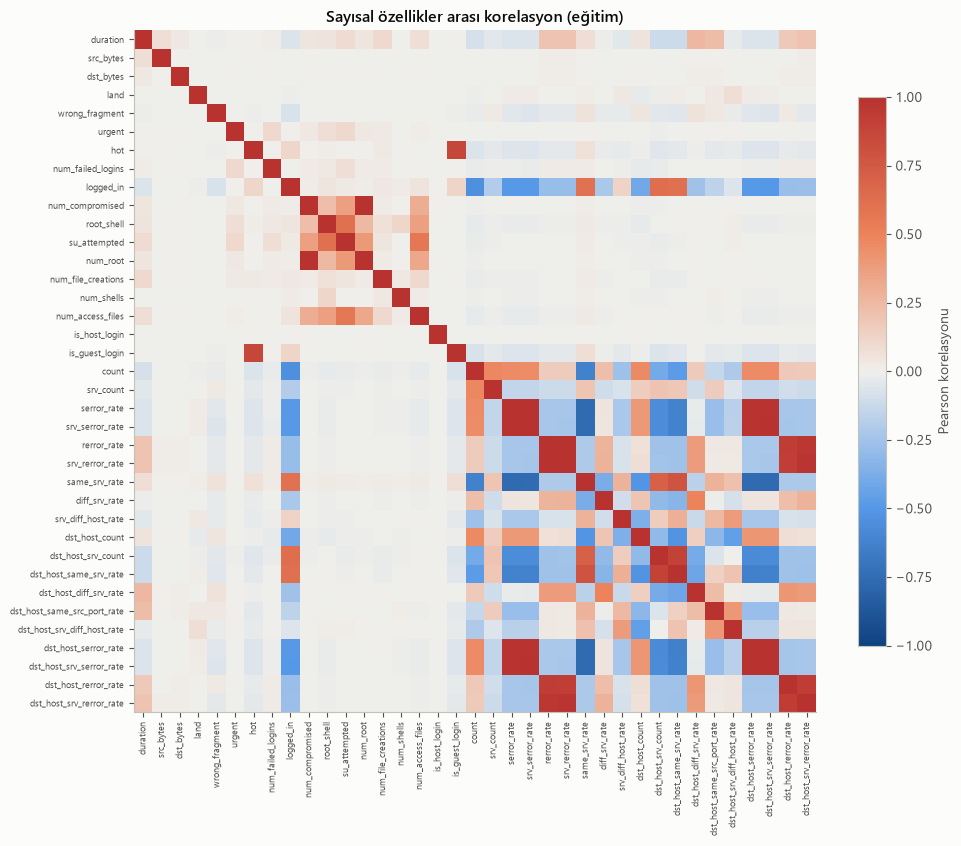

|r| > 0.95 olan özellik çiftleri: 10


,Özellik 1,Özellik 2,r
345,num_compromised,num_root,0.999
761,serror_rate,srv_serror_rate,0.993
837,rerror_rate,srv_rerror_rate,0.989
811,srv_serror_rate,dst_host_srv_serror_rate,0.986
1255,dst_host_serror_rate,dst_host_srv_serror_rate,0.985
774,serror_rate,dst_host_srv_serror_rate,0.981
773,serror_rate,dst_host_serror_rate,0.979
810,srv_serror_rate,dst_host_serror_rate,0.978
887,srv_rerror_rate,dst_host_srv_rerror_rate,0.970
850,rerror_rate,dst_host_srv_rerror_rate,0.964


In [10]:
num_for_corr = [c for c in FEATURE_COLUMNS if c not in cat_cols and train[c].nunique() > 1]
corr = train[num_for_corr].corr()
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_for_corr)), num_for_corr, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(num_for_corr)), num_for_corr, fontsize=6.5)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.set_label('Pearson korelasyonu')
ax.set_title('Sayısal özellikler arası korelasyon (eğitim)')
finish(fig, '05_korelasyon')

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('r').reset_index().assign(abs_r=lambda d: d['r'].abs())
         .sort_values('abs_r', ascending=False))
print('|r| > 0.95 olan özellik çiftleri:', (pairs['abs_r'] > 0.95).sum())
display(pairs.head(10)[['level_0', 'level_1', 'r']].round(3).rename(columns={'level_0': 'Özellik 1', 'level_1': 'Özellik 2'}))

**Gözlem:** SYN hatası (`*serror_rate`) ve REJ hatası (`*rerror_rate`) sütun grupları kendi içinde neredeyse aynı bilgiyi taşır (r > 0.95). Ağaç modelleri bundan etkilenmediği ve LR'de düzenlileştirme kullanıldığı için sütunlar korunmuştur.

## 3. Ön işleme

Uygulanan adımlar ve gerekçeleri:

| Adım | Uygulama | Gerekçe |
|---|---|---|
| Sütun çıkarma | `num_outbound_cmds` (sabit), `difficulty` | Bilgi taşımıyor / etiketle ilgili bilgi içerdiği için **sızıntı** yaratır |
| Hedef | 5 sınıf (Normal, DoS, Probe, R2L, U2R); ikili hedef `P(saldırı) = 1 − P(Normal)` | Hem tür hem de saldırı/normal kararı |
| Log dönüşümü | 1'den büyük değer alan sayım/byte sütunlarına `log(1+x)` | Aşırı çarpık dağılımları sıkıştırır |
| Ölçekleme | `StandardScaler` | Logistic Regression ve autoencoder için gerekli (ağaçlar etkilenmez) |
| Encoding | `OneHotEncoder(handle_unknown='ignore')` | Sahte sıralama oluşmaz; testte yeni kategori çıkarsa hata vermez |
| Dengesizlik | `class_weight='balanced'` (ve karşılaştırma için SMOTE) | Az örnekli sınıfların göz ardı edilmesini önler |
| Bölme | Resmi KDDTrain+/KDDTest+ ayrımı; ayar için eğitim içinde 5 katlı stratified CV | Test kümesi yalnızca en sonda bir kez kullanılır |

Bütün dönüşümler bir `Pipeline` içinde yer alır. Böylece cross-validation'ın her katında encoder ve scaler yalnızca o katın eğitim kısmına fit edilir ve test bilgisi eğitime sızmaz.

In [11]:
CAT_COLS = ['protocol_type', 'service', 'flag']
DROP_COLS = ['num_outbound_cmds']
NUM_COLS = [c for c in FEATURE_COLUMNS if c not in CAT_COLS + DROP_COLS]
LOG_COLS = [c for c in NUM_COLS if train[c].max() > 1]        # sayım ve byte sütunları
LIN_COLS = [c for c in NUM_COLS if c not in LOG_COLS]         # 0-1 aralığındaki oranlar ve ikili bayraklar
FEATURES = CAT_COLS + NUM_COLS

preprocessor = ColumnTransformer([
    ('log', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                      ('scale', StandardScaler())]), LOG_COLS),
    ('lin', StandardScaler(), LIN_COLS),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
])

X_train, X_test = train[FEATURES], test[FEATURES]
y_train = pd.Categorical(train['category'], categories=CLASSES).codes.astype(int)
y_test = pd.Categorical(test['category'], categories=CLASSES).codes.astype(int)
yb_train, yb_test = train['is_attack'].values, test['is_attack'].values

n_out = clone(preprocessor).fit(X_train).transform(X_train.head(1)).shape[1]
print(f'Log dönüşümlü sütun: {len(LOG_COLS)} | doğrudan ölçeklenen: {len(LIN_COLS)} | kategorik: {len(CAT_COLS)}')
print('Ön işleme sonrası özellik sayısı:', n_out)
print('Log dönüşümü uygulanan sütunlar:', LOG_COLS)

Log dönüşümlü sütun: 17 | doğrudan ölçeklenen: 20 | kategorik: 3
Ön işleme sonrası özellik sayısı: 121
Log dönüşümü uygulanan sütunlar: ['duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'num_compromised', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'count', 'srv_count', 'dst_host_count', 'dst_host_srv_count']


### 3.1 PCA ile iki boyutlu görselleştirme
Ön işlenmiş eğitim verisi PCA ile iki boyuta indirildi. Her panelde tüm noktalar gri, ilgili sınıf renkli gösterilmiştir.

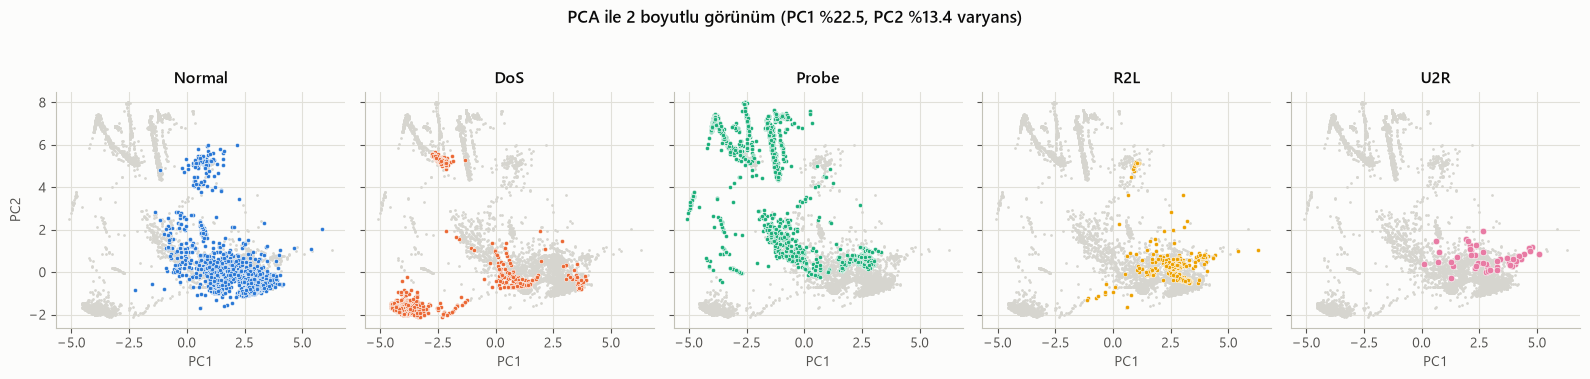

In [12]:
prep_vis = clone(preprocessor).fit(X_train)
Z_all = prep_vis.transform(X_train)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z_all)
sample_idx = (train.groupby('category', group_keys=False)
              .apply(lambda g: g.sample(min(len(g), 2500), random_state=RANDOM_STATE)).index)
P = pca.transform(Z_all[train.index.get_indexer(sample_idx)])
cats = train.loc[sample_idx, 'category'].values

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharex=True, sharey=True)
for ax, c in zip(axes, CLASSES):
    ax.scatter(P[:, 0], P[:, 1], s=4, color='#d6d5cf', linewidths=0)
    m = cats == c
    ax.scatter(P[m, 0], P[m, 1], s=9 if c != 'U2R' else 22, color=CLASS_COLORS[c], linewidths=0.4, edgecolors=SURFACE)
    ax.set_title(c)
    ax.set_xlabel('PC1')
axes[0].set_ylabel('PC2')
ev = pca.explained_variance_ratio_ * 100
fig.suptitle(f'PCA ile 2 boyutlu görünüm (PC1 %{ev[0]:.1f}, PC2 %{ev[1]:.1f} varyans)', y=1.04, fontweight=TITLE_W)
fig.tight_layout()
finish(fig, '06_pca')
del Z_all

**Gözlem:** DoS ve Probe belirgin ayrı kümeler oluştururken R2L ve U2R normal trafiğin yoğun olduğu bölgenin içinde kalıyor. Bu, iki boyutta bile bu sınıfların normal trafikten ayrılmasının zor olduğunu gösteriyor.

## 4. Model eğitimi ve hiperparametre ayarı

| Model | Rolü | Dengesizlik yönetimi |
|---|---|---|
| Logistic Regression | Temel (baseline) model, doğrusal karar sınırı | `class_weight='balanced'` |
| Random Forest | Bagging; doğrusal olmayan ilişkiler ve özellik etkileşimleri | `class_weight='balanced_subsample'` |
| XGBoost | Gradient boosting; hataları sırayla düzelten ağaçlar | `sample_weight` (dengeli ağırlıklar) |

Hiperparametreler, eğitim kümesi üzerinde **5 katlı stratified cross-validation** ile `RandomizedSearchCV` kullanılarak seçildi. Optimize edilen metrik **macro F1**'dir; böylece küçük sınıflar (R2L, U2R) da büyük sınıflar kadar etkili olur. Test kümesi bu aşamada hiç kullanılmadı.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(model):
    return Pipeline([('prep', clone(preprocessor)), ('model', model)])

search_setup = {
    'Logistic Regression': dict(
        model=LogisticRegression(max_iter=3000, class_weight='balanced'),
        params={'model__C': [0.01, 0.1, 1, 10, 100]}, n_iter=5, weights=False),
    'Random Forest': dict(
        model=RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE),
        params={'model__n_estimators': [100, 200, 300], 'model__max_depth': [None, 20, 30],
                'model__min_samples_leaf': [1, 2, 5], 'model__max_features': ['sqrt', 0.3]},
        n_iter=8, weights=False),
    'XGBoost': dict(
        model=XGBClassifier(objective='multi:softprob', tree_method='hist', n_jobs=-1,
                            random_state=RANDOM_STATE, eval_metric='mlogloss'),
        params={'model__n_estimators': [200, 400], 'model__max_depth': [4, 6, 8],
                'model__learning_rate': [0.05, 0.1, 0.2], 'model__subsample': [0.8, 1.0],
                'model__colsample_bytree': [0.6, 0.8, 1.0]},
        n_iter=8, weights=True),
}

searches, tuning_rows = {}, []
for name, s in search_setup.items():
    t0 = time.time()
    search = RandomizedSearchCV(make_pipe(s['model']), s['params'], n_iter=s['n_iter'], scoring='f1_macro',
                                cv=cv, n_jobs=1, refit=True, return_train_score=True, random_state=RANDOM_STATE)
    fit_kw = {'model__sample_weight': compute_sample_weight('balanced', y_train)} if s['weights'] else {}
    search.fit(X_train, y_train, **fit_kw)
    searches[name] = search
    i = search.best_index_
    tuning_rows.append({'Model': name,
                        'En iyi parametreler': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
                        'CV train macro F1': search.cv_results_['mean_train_score'][i],
                        'CV val macro F1': search.best_score_,
                        'CV val std': search.cv_results_['std_test_score'][i],
                        'Süre (sn)': round(time.time() - t0)})
    print(f'{name}: CV macro F1 = {search.best_score_:.4f}  ({time.time() - t0:.0f} sn)')

tuning = pd.DataFrame(tuning_rows).set_index('Model')
pd.set_option('display.max_colwidth', 200)
display(tuning.round(4))
tuning.to_csv(RES_DIR / 'tuning.csv')

Logistic Regression: CV macro F1 = 0.7245  (342 sn)


Random Forest: CV macro F1 = 0.9449  (347 sn)


XGBoost: CV macro F1 = 0.9595  (443 sn)


,En iyi parametreler,CV train macro F1,CV val macro F1,CV val std,Süre (sn)
Model,,,,,
Logistic Regression,{'C': 100},0.7369,0.7245,0.0140,342
Random Forest,"{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 30}",0.9832,0.9449,0.0213,347
XGBoost,"{'subsample': 0.8, 'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.2, 'colsample_bytree': 0.8}",0.9980,0.9595,0.0174,443


**Gözlem:** CV'de en iyi model XGBoost (macro F1 0.9595). Logistic Regression'ın CV skoru (0.7245) belirgin şekilde düşük; problem doğrusal bir karar sınırıyla iyi çözülemiyor. Ağaç modellerinde CV train ve validation skorları arasındaki fark küçük (≈ 0.04); eğitim dağılımı içinde ciddi bir overfitting görünmüyor.

## 5. Sınıf dengesizliği: ağırlıksız, `class_weight` ve SMOTE

En iyi Random Forest ayarlarıyla üç yaklaşım karşılaştırıldı. SMOTE, `imblearn` pipeline'ı içinde yer aldığı için **yalnızca her katın eğitim kısmına** uygulanır; validation ve test verisine sentetik örnek eklenmez. SMOTE ile R2L 5.000, U2R 1.000 örneğe tamamlandı.

In [14]:
rf_params = {k.replace('model__', ''): v for k, v in searches['Random Forest'].best_params_.items()}
rf_base = dict(n_jobs=-1, random_state=RANDOM_STATE, **rf_params)
imb_variants = {
    'Ağırlıksız': make_pipe(RandomForestClassifier(**rf_base)),
    'class_weight': make_pipe(RandomForestClassifier(class_weight='balanced_subsample', **rf_base)),
    'SMOTE': ImbPipeline([('prep', clone(preprocessor)),
                          ('smote', SMOTE(sampling_strategy={3: 5000, 4: 1000}, random_state=RANDOM_STATE)),
                          ('model', RandomForestClassifier(**rf_base))]),
}
imb_rows = []
for name, pipe in imb_variants.items():
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=1)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rec = recall_score(y_test, pred, average=None, labels=range(5))
    imb_rows.append({'Yöntem': name, 'CV macro F1': cvres['test_score'].mean(),
                     'Test macro F1': f1_score(y_test, pred, average='macro'),
                     'Test R2L recall': rec[3], 'Test U2R recall': rec[4]})
imbalance = pd.DataFrame(imb_rows).set_index('Yöntem')
display(imbalance.round(4))
imbalance.to_csv(RES_DIR / 'imbalance_comparison.csv')

,CV macro F1,Test macro F1,Test R2L recall,Test U2R recall
Yöntem,,,,
Ağırlıksız,0.8948,0.5084,0.0447,0.005
class_weight,0.9449,0.4975,0.0084,0.030
SMOTE,0.9373,0.5370,0.0628,0.080


**Gözlem:** `class_weight` CV skorunu artırsa da testte R2L recall değerini 0.0084 seviyesine düşürdü. SMOTE testte en iyi macro F1'i (0.5370) ve en yüksek R2L/U2R recall'u verdi. Hiçbir yöntem görülmemiş saldırı sorununu çözmüyor; CV'ye göre en iyi görünen yöntem testte en iyi olmayabiliyor.

## 6. Test kümesinde değerlendirme

Her model, CV ile seçilen ayarlarla tüm eğitim verisine yeniden fit edildi ve KDDTest+ üzerinde **bir kez** değerlendirildi.

- **5 sınıflı karar:** en yüksek olasılıklı sınıf.
- **İkili karar:** `P(saldırı) = 1 − P(Normal) ≥ 0.5` ise saldırı.

In [15]:
def fpr_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return fp / (fp + tn)

results = {}
for name in MODELS:
    est = searches[name].best_estimator_
    proba = est.predict_proba(X_test)
    p_att = 1 - proba[:, 0]
    results[name] = {'proba': proba, 'pred': proba.argmax(1), 'p_att': p_att, 'pred_bin': (p_att >= 0.5).astype(int)}

multi_rows = []
for name in MODELS:
    p = results[name]['pred']
    multi_rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, p),
                       'Macro Precision': precision_score(y_test, p, average='macro', zero_division=0),
                       'Macro Recall': recall_score(y_test, p, average='macro'),
                       'Macro F1': f1_score(y_test, p, average='macro'),
                       'Weighted F1': f1_score(y_test, p, average='weighted')})
multi = pd.DataFrame(multi_rows).set_index('Model')
print('5 sınıflı sonuçlar (KDDTest+)')
display(multi.round(4))
multi.to_csv(RES_DIR / 'test_multiclass.csv')

per_class = pd.DataFrame({name: recall_score(y_test, results[name]['pred'], average=None, labels=range(5))
                          for name in MODELS}, index=CLASSES)
per_class_f1 = pd.DataFrame({name: f1_score(y_test, results[name]['pred'], average=None, labels=range(5))
                             for name in MODELS}, index=CLASSES)
print('Sınıf bazında recall')
display(per_class.round(3))
print('Sınıf bazında F1')
display(per_class_f1.round(3))
per_class.to_csv(RES_DIR / 'test_per_class_recall.csv')

5 sınıflı sonuçlar (KDDTest+)


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,
Logistic Regression,0.7608,0.6400,0.5607,0.5686,0.7446
Random Forest,0.7634,0.7317,0.5020,0.4975,0.7155
XGBoost,0.7853,0.8503,0.5384,0.5689,0.7554


Sınıf bazında recall


,Logistic Regression,Random Forest,XGBoost
Normal,0.904,0.971,0.973
DoS,0.795,0.817,0.841
Probe,0.749,0.683,0.644
R2L,0.221,0.008,0.149
U2R,0.135,0.030,0.085


Sınıf bazında F1


,Logistic Regression,Random Forest,XGBoost
Normal,0.791,0.792,0.806
DoS,0.874,0.884,0.898
Probe,0.674,0.739,0.728
R2L,0.334,0.017,0.259
U2R,0.169,0.056,0.153


In [16]:
def binary_row(name, y_true, pred, score):
    return {'Model': name, 'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred),
            'Recall (DR)': recall_score(y_true, pred), 'F1': f1_score(y_true, pred),
            'FPR': fpr_score(y_true, pred), 'ROC-AUC': roc_auc_score(y_true, score),
            'PR-AUC': average_precision_score(y_true, score)}

binary = pd.DataFrame([binary_row(n, yb_test, results[n]['pred_bin'], results[n]['p_att']) for n in MODELS]).set_index('Model')
print('İkili sonuçlar (KDDTest+, eşik 0.5)')
display(binary.round(4))

gap = tuning[['CV train macro F1', 'CV val macro F1']].join(multi['Macro F1'].rename('Test macro F1'))
gap['Val − Test farkı'] = gap['CV val macro F1'] - gap['Test macro F1']
print('Cross-validation ve test karşılaştırması (macro F1)')
display(gap.round(4))
gap.to_csv(RES_DIR / 'cv_vs_test.csv')

best_name = tuning['CV val macro F1'].idxmax()
print('CV skoruna göre seçilen model:', best_name)

İkili sonuçlar (KDDTest+, eşik 0.5)

,Accuracy,Precision,Recall (DR),F1,FPR,ROC-AUC,PR-AUC
Model,,,,,,,
Logistic Regression,0.7966,0.9075,0.7156,0.8002,0.0964,0.8955,0.9005
Random Forest,0.7932,0.9679,0.6585,0.7838,0.0288,0.9677,0.9696
XGBoost,0.7981,0.9698,0.6661,0.7898,0.0274,0.9621,0.9597


Cross-validation ve test karşılaştırması (macro F1)


,CV train macro F1,CV val macro F1,Test macro F1,Val − Test farkı
Model,,,,
Logistic Regression,0.7369,0.7245,0.5686,0.1559
Random Forest,0.9832,0.9449,0.4975,0.4474
XGBoost,0.9980,0.9595,0.5689,0.3907


CV skoruna göre seçilen model: XGBoost


**Gözlem:** 5 sınıflı problemde en yüksek test macro F1 değeri XGBoost'a (0.5689) ait, LR neredeyse aynı skoru alıyor ve R2L/U2R'de en yüksek recall'u veriyor. **CV ile test arasındaki fark çok büyük** (XGBoost: 0.9595 → 0.5689). Bunun nedeni overfitting'den çok, test kümesindeki dağılım farkı ve yeni saldırı türleri. İkili problemde RF ve XGBoost çok az yanlış alarm veriyor (FPR ≈ %2.7) ama saldırıların yalnızca üçte ikisini yakalıyor.

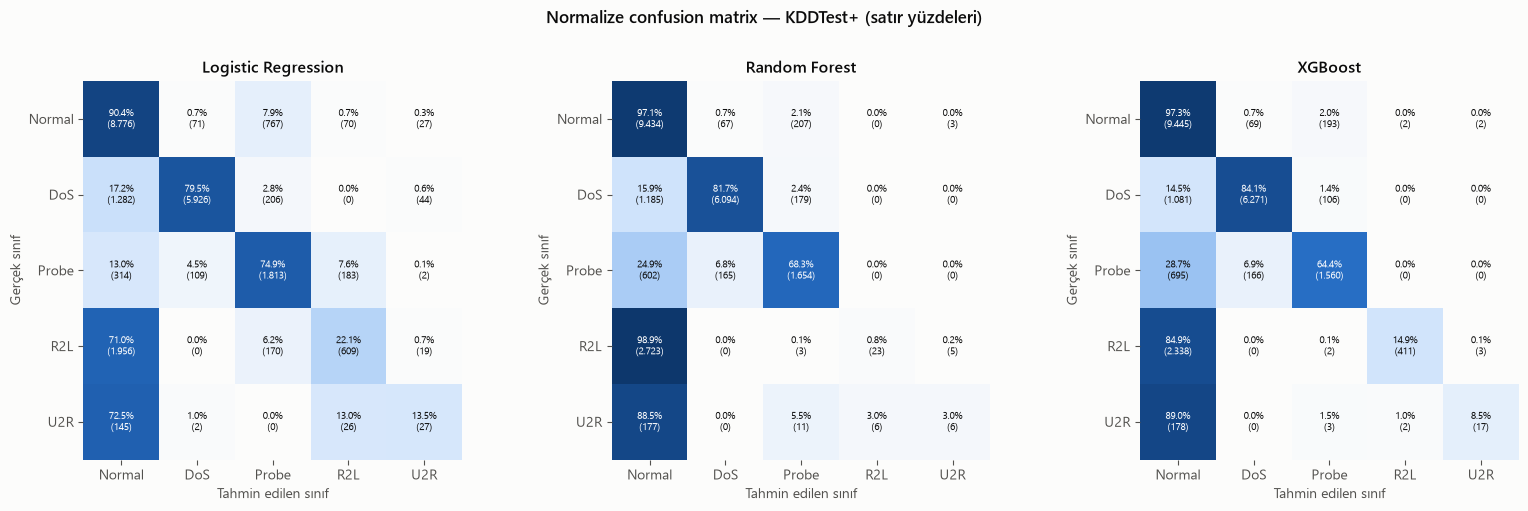

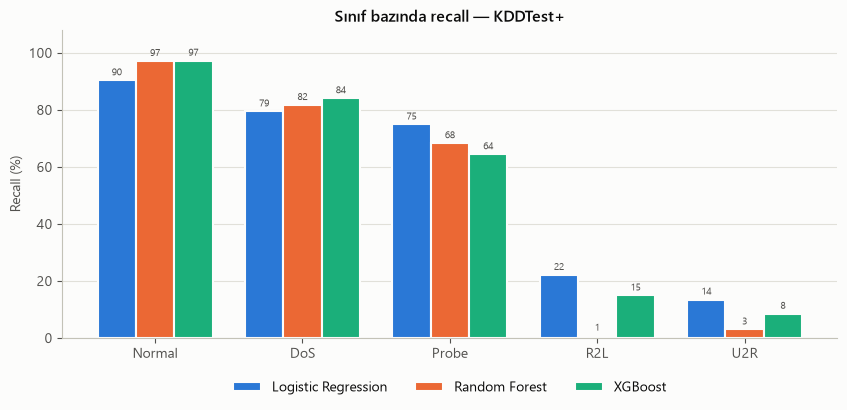

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9))
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(y_test, results[name]['pred'], labels=range(5))
    cmn = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(cmn, cmap=SEQ_CMAP, vmin=0, vmax=100)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f'{cmn[i, j]:.1f}%\n({tr_int(cm[i, j])})', ha='center', va='center', fontsize=7.5,
                    color='white' if cmn[i, j] > 55 else INK)
    ax.set_xticks(range(5), CLASSES); ax.set_yticks(range(5), CLASSES)
    ax.set_xlabel('Tahmin edilen sınıf'); ax.set_ylabel('Gerçek sınıf')
    ax.set_title(name); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle('Normalize confusion matrix — KDDTest+ (satır yüzdeleri)', y=1.02, fontweight=TITLE_W)
fig.tight_layout()
finish(fig, '07_confusion_matrix')

fig, ax = plt.subplots(figsize=(10, 4))
x, w = np.arange(5), 0.26
for i, name in enumerate(MODELS):
    bars = ax.bar(x + (i - 1) * w, per_class[name] * 100, width=w, color=MODEL_COLORS[name],
                  edgecolor=SURFACE, linewidth=1.5, label=name)
    ax.bar_label(bars, labels=[f'{v * 100:.0f}' for v in per_class[name]], padding=2, fontsize=7.5, color=INK2)
ax.set_xticks(x, CLASSES)
ax.set_ylabel('Recall (%)'); ax.set_ylim(0, 108)
ax.set_title('Sınıf bazında recall — KDDTest+')
ax.grid(axis='x', visible=False)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
finish(fig, '08_sinif_recall')

**Gözlem:** Normal ve DoS tüm modellerde iyi tanınıyor; R2L ve U2R kayıtlarının büyük çoğunluğu **Normal** olarak tahmin ediliyor. Bu IDS için en tehlikeli hata türü: saldırı var ama alarm yok.

### 6.1 Karar eşiği analizi (ikili)
Varsayılan eşik 0.5'tir. Eşik düşürüldükçe daha fazla saldırı yakalanır (recall artar) ama yanlış alarm oranı (FPR) da artar. Bu grafik **eşik seçmek için değil**, bu dengeyi göstermek için test kümesinde çizilmiştir; raporlanan ana sonuçlar 0.5 eşiğiyle elde edilmiştir.

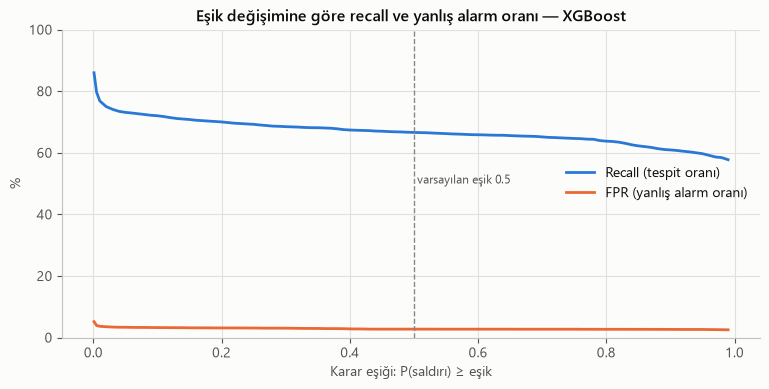

,Recall,FPR,Precision
Eşik,,,
0.001,0.8597,0.0518,0.9564
0.010,0.7683,0.0367,0.9652
0.050,0.7312,0.0335,0.9665
0.100,0.7203,0.0324,0.9670
0.200,0.7001,0.0313,0.9673
0.300,0.6848,0.0305,0.9674
0.400,0.6740,0.0282,0.9693
0.500,0.6661,0.0274,0.9698
0.700,0.6515,0.0272,0.9694


In [18]:
thr_grid = np.concatenate([[0.001, 0.005], np.round(np.arange(0.01, 0.995, 0.01), 2)])
p = results[best_name]['p_att']
thr_df = pd.DataFrame({'Eşik': thr_grid,
                       'Recall': [recall_score(yb_test, (p >= t).astype(int)) for t in thr_grid],
                       'FPR': [fpr_score(yb_test, (p >= t).astype(int)) for t in thr_grid],
                       'Precision': [precision_score(yb_test, (p >= t).astype(int), zero_division=0) for t in thr_grid]})

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thr_df['Eşik'], thr_df['Recall'] * 100, color=PALETTE[0], label='Recall (tespit oranı)')
ax.plot(thr_df['Eşik'], thr_df['FPR'] * 100, color=PALETTE[1], label='FPR (yanlış alarm oranı)')
ax.axvline(0.5, color=MUTED, linestyle='--', linewidth=1)
ax.text(0.505, 50, 'varsayılan eşik 0.5', color=INK2, fontsize=8.5)
ax.set_xlabel('Karar eşiği: P(saldırı) ≥ eşik'); ax.set_ylabel('%'); ax.set_ylim(0, 100)
ax.set_title(f'Eşik değişimine göre recall ve yanlış alarm oranı — {best_name}')
ax.legend(loc='center right')
finish(fig, '09_esik_analizi')
thr_df.set_index('Eşik').to_csv(RES_DIR / 'threshold.csv')
display(thr_df[thr_df['Eşik'].isin([0.001, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 0.9])].round(4).set_index('Eşik'))

**Gözlem:** Eşiği 0.5 yerine 0.05 yapmak tespit oranını yalnızca birkaç puan artırıyor; anlamlı artış ancak 0.001 gibi aşırı düşük eşiklerde görülüyor. XGBoost, kaçırdığı saldırıların çoğuna neredeyse sıfır saldırı olasılığı veriyor; sorun eşikte değil, modelin bu örüntüleri eğitimde hiç görmemiş olmasında.

## 7. Hata analizi

### 7.1 En sık karıştırılan sınıflar

In [19]:
cm_best = confusion_matrix(y_test, results[best_name]['pred'], labels=range(5))
conf = [(CLASSES[i], CLASSES[j], cm_best[i, j], 100 * cm_best[i, j] / cm_best[i].sum())
        for i in range(5) for j in range(5) if i != j and cm_best[i, j] > 0]
conf = pd.DataFrame(conf, columns=['Gerçek', 'Tahmin', 'Kayıt', '% (gerçek sınıfın)']).sort_values('Kayıt', ascending=False)
print(f'{best_name} — en sık hatalar')
display(conf.head(8).round(1).reset_index(drop=True))

XGBoost — en sık hatalar


,Gerçek,Tahmin,Kayıt,% (gerçek sınıfın)
0,R2L,Normal,2338,84.9
1,DoS,Normal,1081,14.5
2,Probe,Normal,695,28.7
3,Normal,Probe,193,2.0
4,U2R,Normal,178,89.0
5,Probe,DoS,166,6.9
6,DoS,Probe,106,1.4
7,Normal,DoS,69,0.7


**Gözlem:** Hataların ezici çoğunluğu saldırıların **Normal** olarak tahmin edilmesinden kaynaklanıyor; saldırı kategorilerinin birbiriyle karıştırılması çok daha az.

### 7.2 Eğitimde görülen ve hiç görülmeyen saldırı türleri
Testteki saldırılar, saldırı türünün (`label`) eğitim kümesinde bulunup bulunmamasına göre ikiye ayrıldı. Tespit oranı = saldırının (türü ne olursa olsun) saldırı olarak işaretlenme oranı.

In [20]:
att_mask = yb_test == 1
seen_mask = test['seen_in_train'].values
def detection_by_group(pred_bin):
    return {'Görülen türler': pred_bin[att_mask & seen_mask].mean(), 'Görülmeyen türler': pred_bin[att_mask & ~seen_mask].mean()}
seen_unseen = pd.DataFrame({n: detection_by_group(results[n]['pred_bin']) for n in MODELS}).T
display((seen_unseen * 100).round(1))

attack_types = (test[att_mask].assign(detected=results[best_name]['pred_bin'][att_mask],
                                      correct_cat=(results[best_name]['pred'] == y_test)[att_mask])
                .groupby(['label', 'category', 'seen_in_train'])
                .agg(Kayıt=('detected', 'size'), Tespit_orani=('detected', 'mean'), Dogru_kategori=('correct_cat', 'mean'))
                .reset_index().sort_values('Kayıt', ascending=False))
attack_types[['Tespit_orani', 'Dogru_kategori']] = (attack_types[['Tespit_orani', 'Dogru_kategori']] * 100).round(1)
attack_types['Kaçırılan'] = (attack_types['Kayıt'] * (100 - attack_types['Tespit_orani']) / 100).round().astype(int)
attack_types.to_csv(RES_DIR / 'attack_type_detection.csv', index=False)
print(f'{best_name} — en çok kaçırılan saldırı türleri')
display(attack_types.sort_values('Kaçırılan', ascending=False).head(12).reset_index(drop=True))

,Görülen türler,Görülmeyen türler
Logistic Regression,82.6,44.8
Random Forest,75.9,41.5
XGBoost,79.9,34.4


XGBoost — en çok kaçırılan saldırı türleri


,label,category,seen_in_train,Kayıt,Tespit_orani,Dogru_kategori,Kaçırılan
0,guess_passwd,R2L,True,1231,0.0,0.0,1231
1,mscan,Probe,False,996,30.7,13.8,690
2,processtable,DoS,False,685,12.0,0.0,603
3,warezmaster,R2L,True,944,43.4,43.2,534
4,snmpguess,R2L,False,331,0.0,0.0,331
5,mailbomb,DoS,False,293,0.0,0.0,293
6,snmpgetattack,R2L,False,178,0.0,0.0,178
7,apache2,DoS,False,737,76.7,76.7,172
8,httptunnel,U2R,False,133,2.3,0.0,130
9,multihop,R2L,True,18,11.1,0.0,16


**Gözlem:** XGBoost modelinin tespit oranı eğitimde görülen türlerde %79.9, hiç görülmeyen türlerde ise yalnızca %34.4. En çok kaçırılan tür `guess_passwd`: eğitimde çok az örneği var ve testteki 1231 kaydın hiçbiri yakalanamadı. Yeni türlerden `mailbomb`, `snmpguess`, `snmpgetattack` hiç yakalanamadı.

### 7.3 Kaçırılan R2L saldırıları normal trafikten neden ayırt edilemiyor?
Kaçırılan (Normal tahmin edilen) R2L bağlantılarının bazı özellik medyanları, doğru yakalanan R2L'ler ve normal trafikle karşılaştırıldı.

In [21]:
pred_best = results[best_name]['pred']
r2l = y_test == 3
groups = {'Normal (gerçek)': y_test == 0, 'R2L — yakalanan': r2l & (pred_best != 0), 'R2L — kaçırılan': r2l & (pred_best == 0)}
cmp_cols = ['duration', 'src_bytes', 'dst_bytes', 'hot', 'num_failed_logins', 'logged_in', 'count', 'dst_host_count',
            'dst_host_srv_count', 'dst_host_same_srv_rate']
r2l_cmp = pd.DataFrame({g: test.loc[m, cmp_cols].median() for g, m in groups.items()}).T
r2l_cmp.insert(0, 'Kayıt', [int(m.sum()) for m in groups.values()])
display(r2l_cmp.round(2))
print('Kaçırılan R2L kayıtlarının servis dağılımı:')
display(test.loc[groups['R2L — kaçırılan'], 'service'].value_counts().head(5))

,Kayıt,duration,src_bytes,dst_bytes,hot,num_failed_logins,logged_in,count,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate
Normal (gerçek),9711,0.0,236.0,740.0,0.0,0.0,1.0,6.0,188.0,255.0,1.00
R2L — yakalanan,416,280.0,160.0,0.0,0.0,0.0,0.0,1.0,6.0,18.5,1.00
R2L — kaçırılan,2338,3.0,47.0,93.0,0.0,0.0,0.0,1.0,255.0,159.0,0.88


Kaçırılan R2L kayıtlarının servis dağılımı:


service
pop_3       750
private     498
ftp         479
telnet      398
ftp_data    163
Name: count, dtype: int64

**Gözlem:** Kaçırılan R2L bağlantıları; kısa süreli, küçük byte miktarlı ve tek bağlantılık (`count` = 1) oturumlar. Hedef host istatistikleri ise normal trafiğe çok benziyor. Saldırının izi paket içeriğinde (ör. denenen parola) olduğu için trafik istatistikleriyle yakalanması zor; ağırlıklı olarak pop_3, ftp ve telnet servislerinde yoğunlaşıyorlar.

### 7.4 Özellik önemi

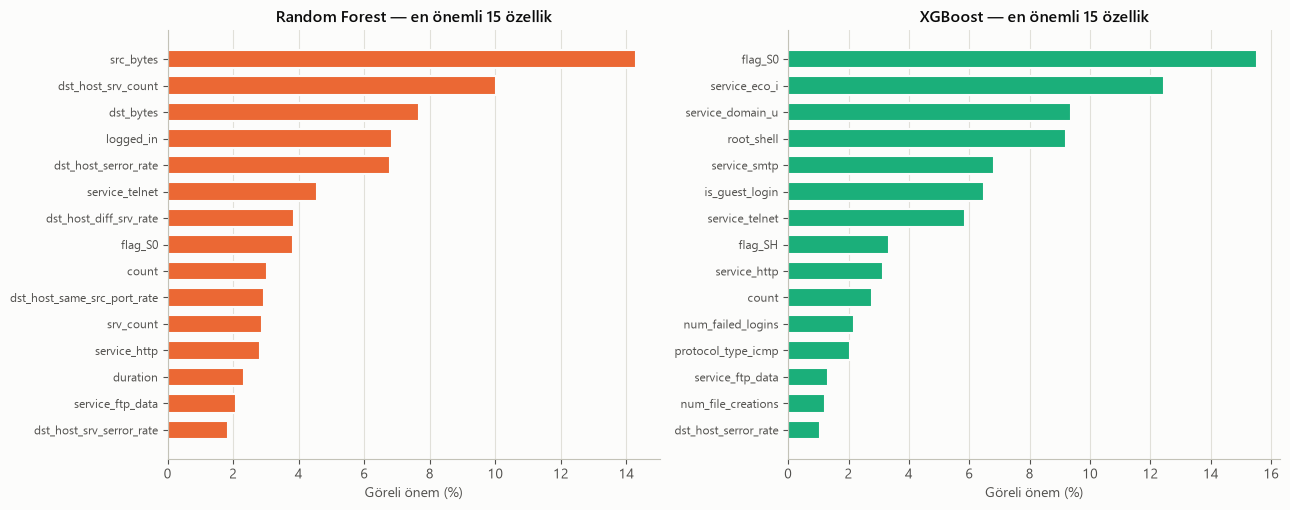

In [22]:
def importances(name):
    est = searches[name].best_estimator_
    names = [n.split('__', 1)[1] for n in est['prep'].get_feature_names_out()]
    return pd.Series(est['model'].feature_importances_, index=names).sort_values(ascending=False)

imp = {n: importances(n) for n in ['Random Forest', 'XGBoost']}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (name, s) in zip(axes, imp.items()):
    top = s.head(15)[::-1]
    ax.barh(top.index, top.values / s.sum() * 100, color=MODEL_COLORS[name], edgecolor=SURFACE, linewidth=1.5, height=0.7)
    ax.set_xlabel('Göreli önem (%)')
    ax.set_title(f'{name} — en önemli 15 özellik')
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', labelsize=8.5)
fig.tight_layout()
finish(fig, '10_ozellik_onemi')
pd.DataFrame({n: s.head(15).index for n, s in imp.items()}).to_csv(RES_DIR / 'top_features.csv', index=False)

**Gözlem:** Random Forest en çok byte miktarlarına ve host tabanlı istatistiklere (`dst_host_srv_count`), XGBoost ise `flag_S0` (SYN flood), belirli servisler (`eco_i` → ICMP taraması) ve `root_shell` (U2R) gibi doğrudan saldırı imzası taşıyan özelliklere dayanıyor. Önemli özellikler alan bilgisiyle tutarlı.

## 8. Autoencoder ile anomali tespiti

Denetimli modeller yalnızca eğitimde gördükleri saldırıları öğrenebilir. Autoencoder ise **yalnızca normal trafikle** eğitilir ve normal trafiği yeniden üretmeyi öğrenir. Görmediği türden bir bağlantıyı iyi üretemez; **yeniden üretim hatası (MSE)** yükselir. Hata eşiği aşarsa bağlantı anomali (saldırı) sayılır.

- **Mimari:** girdi (≈120) → 64 → **16 (darboğaz)** → 64 → çıktı; gizli katmanlarda ReLU, çıkışta doğrusal aktivasyon
- **Loss:** MSE · **Optimizer:** Adam (lr = 0.001) · **Batch:** 256 · **L2 düzenlileştirme:** alpha = 1e-4
- **Veri bölme (yalnızca normal eğitim kayıtları):** %81 eğitim, %9 early stopping doğrulaması, %10 eşik belirleme
- **Early stopping:** Her epoch sonunda doğrulama MSE'si ölçülür; 10 epoch iyileşme olmazsa eğitim durur ve en iyi epoch'un ağırlıkları kullanılır (en fazla 100 epoch)
- **Ön işleme:** Aynı pipeline, fakat **sadece normal eğitim verisine** fit edildi
- **Eşik:** Ayrı tutulan %10'luk normal veride yeniden üretim hatasının **95. persantili** (yani normal trafikte hedeflenen yanlış alarm oranı ≈ %5)

Autoencoder: 91 epoch çalıştı, en iyi doğrulama MSE 0.1438 (epoch 81), 78 sn


,Eğitim (örneklem),Doğrulama
Ortalama MSE,0.0068,0.1438
Medyan MSE,0.0010,0.0010
Ortalama (en uç %0.5 hariç),0.0050,0.0052
Maksimum,2.3153,807.0270


Eşik (normal hold-out, 95. persantil): 0.0255


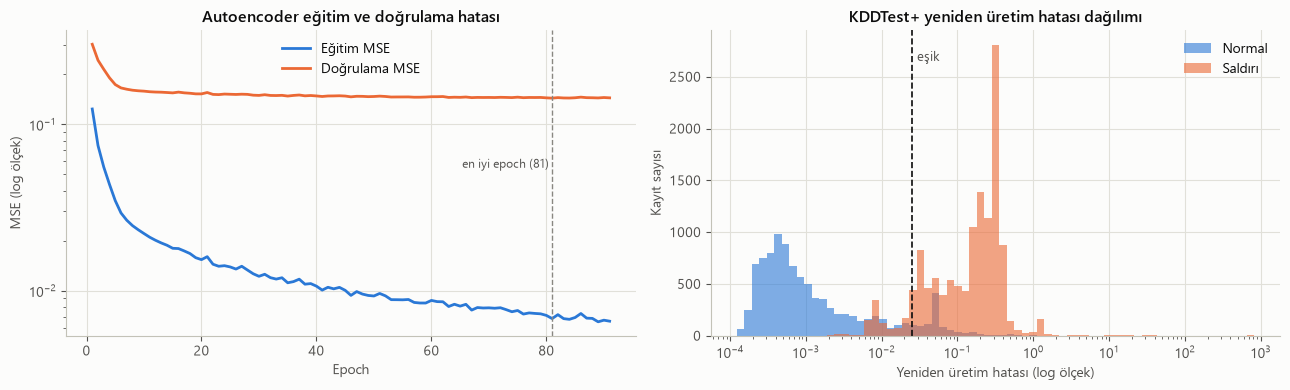

In [23]:
X_norm = X_train[y_train == 0]
Xn_fit, Xn_hold = train_test_split(X_norm, test_size=0.1, random_state=RANDOM_STATE)
ae_prep = clone(preprocessor).fit(Xn_fit)
Zn_fit = ae_prep.transform(Xn_fit)

Zn_tr, Zn_val = train_test_split(Zn_fit, test_size=0.1, random_state=RANDOM_STATE)

# Early stopping doğrulama MSE'sine göre elle yapılır: her epoch sonunda doğrulama hatası ölçülür,
# 10 epoch iyileşme olmazsa durulur ve en iyi epoch'un ağırlıkları kullanılır.
import copy
ae = MLPRegressor(hidden_layer_sizes=(64, 16, 64), activation='relu', solver='adam', learning_rate_init=1e-3,
                  batch_size=256, alpha=1e-4, shuffle=True, random_state=RANDOM_STATE)
MAX_EPOCHS, PATIENCE = 100, 10
history, best_val, best_epoch, wait, best_ae = [], np.inf, 0, 0, None
Zn_tr_sample = Zn_tr[np.random.RandomState(RANDOM_STATE).choice(len(Zn_tr), len(Zn_val), replace=False)]
t0 = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    ae.partial_fit(Zn_tr, Zn_tr)
    val_mse = np.mean((ae.predict(Zn_val) - Zn_val) ** 2)
    train_mse = np.mean((ae.predict(Zn_tr_sample) - Zn_tr_sample) ** 2)   # aynı ölçü, eğitim verisinden örneklem
    history.append((epoch, train_mse, val_mse))
    if val_mse < best_val - 1e-5:
        best_val, best_epoch, wait, best_ae = val_mse, epoch, 0, copy.deepcopy(ae)
    else:
        wait += 1
        if wait >= PATIENCE:
            break
ae = best_ae
history = pd.DataFrame(history, columns=['epoch', 'train_mse', 'val_mse'])
AE_EPOCHS = best_epoch
print(f'Autoencoder: {len(history)} epoch çalıştı, en iyi doğrulama MSE {best_val:.4f} (epoch {best_epoch}), '
      f'{time.time() - t0:.0f} sn')

# Ortalama MSE birkaç uç kayda çok duyarlıdır; overfitting olup olmadığını medyan hatayla kontrol ediyoruz.
row_err = lambda Z: np.mean((ae.predict(Z) - Z) ** 2, axis=1)
err_tr_s, err_val = row_err(Zn_tr_sample), row_err(Zn_val)
AE_DIAG = {'median_train': float(np.median(err_tr_s)), 'median_val': float(np.median(err_val)),
           'mean_train': float(err_tr_s.mean()), 'mean_val': float(err_val.mean()), 'max_val': float(err_val.max()),
           'mean_val_trim': float(err_val[err_val < np.percentile(err_val, 99.5)].mean()),
           'mean_train_trim': float(err_tr_s[err_tr_s < np.percentile(err_tr_s, 99.5)].mean())}
display(pd.DataFrame({'Eğitim (örneklem)': [AE_DIAG['mean_train'], AE_DIAG['median_train'], AE_DIAG['mean_train_trim'], err_tr_s.max()],
                      'Doğrulama': [AE_DIAG['mean_val'], AE_DIAG['median_val'], AE_DIAG['mean_val_trim'], AE_DIAG['max_val']]},
                     index=['Ortalama MSE', 'Medyan MSE', 'Ortalama (en uç %0.5 hariç)', 'Maksimum']).round(4))

def recon_error(X):
    Z = ae_prep.transform(X)
    return np.mean((ae.predict(Z) - Z) ** 2, axis=1)

AE_THRESHOLD = np.percentile(recon_error(Xn_hold), 95)
err_test = recon_error(X_test)
ae_pred = (err_test >= AE_THRESHOLD).astype(int)
print(f'Eşik (normal hold-out, 95. persantil): {AE_THRESHOLD:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history['epoch'], history['train_mse'], color=PALETTE[0], label='Eğitim MSE')
axes[0].plot(history['epoch'], history['val_mse'], color=PALETTE[1], label='Doğrulama MSE')
axes[0].set_yscale('log')
axes[0].axvline(AE_EPOCHS, color=MUTED, linestyle='--', linewidth=1)
ylo, yhi = axes[0].get_ylim()
axes[0].text(AE_EPOCHS, ylo * (yhi / ylo) ** 0.55, f'en iyi epoch ({AE_EPOCHS}) ', color=INK2, fontsize=8.5, ha='right')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE (log ölçek)')
axes[0].set_title('Autoencoder eğitim ve doğrulama hatası'); axes[0].legend(loc='upper center')
bins = np.logspace(np.log10(max(err_test.min(), 1e-4)), np.log10(err_test.max()), 70)
for lab, m, col in [('Normal', yb_test == 0, PALETTE[0]), ('Saldırı', yb_test == 1, PALETTE[1])]:
    axes[1].hist(err_test[m], bins=bins, color=col, alpha=0.6, label=lab)
axes[1].axvline(AE_THRESHOLD, color=INK, linestyle='--', linewidth=1.2)
axes[1].text(AE_THRESHOLD * 1.15, axes[1].get_ylim()[1] * 0.9, 'eşik', color=INK2, fontsize=9)
axes[1].set_xscale('log'); axes[1].set_xlabel('Yeniden üretim hatası (log ölçek)'); axes[1].set_ylabel('Kayıt sayısı')
axes[1].set_title('KDDTest+ yeniden üretim hatası dağılımı'); axes[1].legend()
fig.tight_layout()
finish(fig, '11_autoencoder')

**Gözlem:** Grafikte doğrulama MSE'si eğitimden çok yüksek görünse de bu overfitting değildir: medyan hata eğitimde 0.0010, doğrulamada 0.0010. Ortalama farkı, doğrulama kümesindeki birkaç uç kayıttan kaynaklanıyor (en büyük hata 807); en uç %0.5 çıkarıldığında ortalamalar 0.0050 ve 0.0052. Bu yüzden early stopping ölçütü olarak medyan veya kırpılmış ortalama daha sağlam bir seçim olurdu.

**Gözlem:** Normal ve saldırı kayıtlarının yeniden üretim hataları büyük ölçüde ayrışıyor. Normal veride belirlenen eşikle autoencoder'ın testteki tespit oranı %91.3, yanlış alarm oranı %10.0. Eşik, eğitimdeki normal trafikte yanlış alarm oranı %5 olacak şekilde seçilmişti; testteki farklılık, test kümesindeki normal trafiğin de eğitimdekinden farklı olduğunu gösteriyor. Gerçek kullanımda eşik, ağın güncel normal trafiğiyle yeniden kalibre edilmelidir.

## 9. İkili tespit: tüm yöntemlerin karşılaştırması

**Hibrit** yaklaşım: en iyi denetimli model **veya** autoencoder saldırı derse alarm verilir. Amaç, denetimli modelin bilinen saldırılardaki başarısını autoencoder'ın görülmemiş saldırıları yakalama yeteneğiyle birleştirmektir.

In [24]:
hybrid_pred = ((results[best_name]['pred_bin'] == 1) | (ae_pred == 1)).astype(int)
rows = [binary_row(n, yb_test, results[n]['pred_bin'], results[n]['p_att']) for n in MODELS]
rows.append(binary_row('Autoencoder', yb_test, ae_pred, err_test))
h = binary_row(f'Hibrit', yb_test, hybrid_pred, hybrid_pred)
h['ROC-AUC'] = h['PR-AUC'] = np.nan
rows.append(h)
binary_all = pd.DataFrame(rows).set_index('Model')
print(f'Hibrit = {best_name} VEYA Autoencoder')
display(binary_all.round(4))
binary_all.to_csv(RES_DIR / 'test_binary.csv')

seen_unseen.loc['Autoencoder'] = detection_by_group(ae_pred)
seen_unseen.loc['Hibrit'] = detection_by_group(hybrid_pred)
print('Saldırı tespit oranı (%) — eğitimde görülen / görülmeyen türler')
display((seen_unseen * 100).round(1))
seen_unseen.to_csv(RES_DIR / 'seen_unseen_detection.csv')

Hibrit = XGBoost VEYA Autoencoder


,Accuracy,Precision,Recall (DR),F1,FPR,ROC-AUC,PR-AUC
Model,,,,,,,
Logistic Regression,0.7966,0.9075,0.7156,0.8002,0.0964,0.8955,0.9005
Random Forest,0.7932,0.9679,0.6585,0.7838,0.0288,0.9677,0.9696
XGBoost,0.7981,0.9698,0.6661,0.7898,0.0274,0.9621,0.9597
Autoencoder,0.9072,0.9236,0.9126,0.9180,0.0998,0.9701,0.9706
Hibrit,0.9128,0.9241,0.9225,0.9233,0.1001,NaN,NaN


Saldırı tespit oranı (%) — eğitimde görülen / görülmeyen türler


,Görülen türler,Görülmeyen türler
Logistic Regression,82.6,44.8
Random Forest,75.9,41.5
XGBoost,79.9,34.4
Autoencoder,96.3,79.0
Hibrit,97.7,79.1


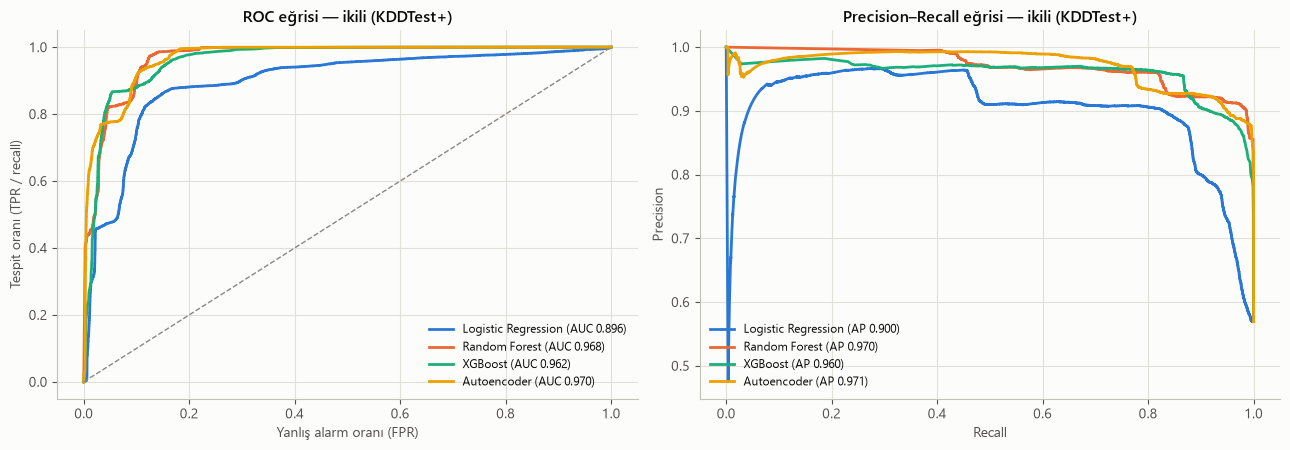

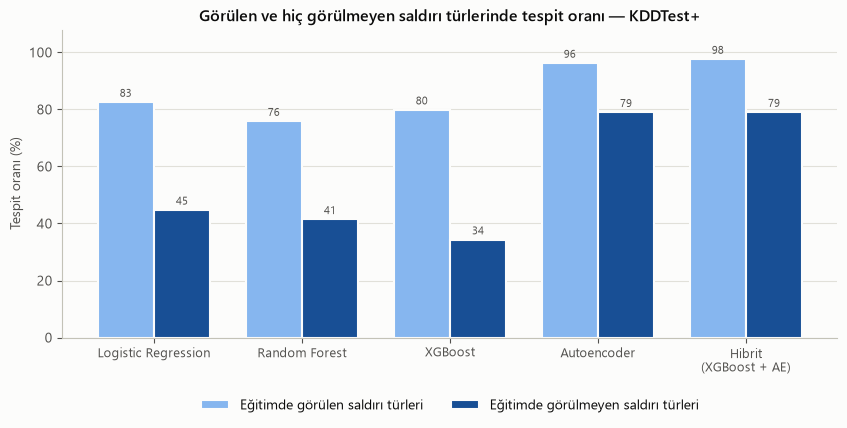

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name in MODELS + ['Autoencoder']:
    score = err_test if name == 'Autoencoder' else results[name]['p_att']
    fpr, tpr, _ = roc_curve(yb_test, score)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], label=f'{name} (AUC {roc_auc_score(yb_test, score):.3f})')
    prec, rec, _ = precision_recall_curve(yb_test, score)
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], label=f'{name} (AP {average_precision_score(yb_test, score):.3f})')
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle='--', linewidth=1)
axes[0].set_xlabel('Yanlış alarm oranı (FPR)'); axes[0].set_ylabel('Tespit oranı (TPR / recall)')
axes[0].set_title('ROC eğrisi — ikili (KDDTest+)'); axes[0].legend(loc='lower right', fontsize=8.5)
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision–Recall eğrisi — ikili (KDDTest+)'); axes[1].legend(loc='lower left', fontsize=8.5)
fig.tight_layout()
finish(fig, '12_roc_pr')

order = MODELS + ['Autoencoder', 'Hibrit']
fig, ax = plt.subplots(figsize=(10, 4))
x, w = np.arange(len(order)), 0.38
for i, (grp, col) in enumerate(zip(['Görülen türler', 'Görülmeyen türler'], SPLIT_COLORS)):
    vals = seen_unseen.loc[order, grp] * 100
    bars = ax.bar(x + (i - 0.5) * w, vals, width=w, color=col, edgecolor=SURFACE, linewidth=1.5,
                  label=f'Eğitimde {grp.split()[0].lower()} saldırı türleri')
    ax.bar_label(bars, labels=[f'{v:.0f}' for v in vals], padding=2, fontsize=8, color=INK2)
ax.set_xticks(x, [o if o != 'Hibrit' else f'Hibrit\n({best_name} + AE)' for o in order], fontsize=9)
ax.set_ylabel('Tespit oranı (%)'); ax.set_ylim(0, 108)
ax.set_title('Görülen ve hiç görülmeyen saldırı türlerinde tespit oranı — KDDTest+')
ax.grid(axis='x', visible=False)
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.16))
finish(fig, '13_gorulen_gorulmeyen')

**Gözlem:** Autoencoder, eğitimde hiç görülmemiş saldırı türlerinde %79.0 tespit oranıyla denetimli modellerin hepsini geride bırakıyor. XGBoost ile autoencoder'ı birleştiren hibrit yapının tespit oranı %92.3, F1 değeri 0.9233; bedeli yanlış alarm oranındaki artış (XGBoost: %2.7 → hibrit: %10.0). Hangi yapının seçileceği kurumun yanlış alarm toleransına bağlıdır.

In [26]:
summary = {
    'n_train': int(len(train)), 'n_test': int(len(test)), 'n_features_after_prep': int(n_out),
    'best_model': best_name, 'ae_threshold': float(AE_THRESHOLD), 'ae_epochs': int(AE_EPOCHS),
    'ae_epochs_run': int(len(history)), 'ae_diag': AE_DIAG,
    'unseen_attack_share_test': n_unseen / n_attack_test,
    'tuning': tuning.drop(columns=['En iyi parametreler']).round(4).to_dict('index'),
    'best_params': {k: {p: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for p, v in d.items()}
                    for k, d in tuning['En iyi parametreler'].items()},
    'multiclass': multi.round(4).to_dict('index'), 'binary': binary_all.round(4).to_dict('index'),
    'per_class_recall': per_class.round(4).to_dict(), 'seen_unseen': seen_unseen.round(4).to_dict('index'),
    'imbalance': imbalance.round(4).to_dict('index'),
}
(RES_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
print('Sonuçlar kaydedildi:', RES_DIR)

Sonuçlar kaydedildi: C:\Users\bzkr_\OneDrive\Masaüstü\Staj\ML IDS\results


## 10. Sonuç

- Ağaç tabanlı modeller eğitimde görülen saldırıları (özellikle DoS ve Probe) yüksek doğruluk ve düşük yanlış alarmla tespit ediyor.
- Resmi test kümesi, denetimli modellerin **yeni saldırı türlerinde** ve az örnekli **R2L/U2R** sınıflarında zayıf kaldığını gösterdi; CV skorları gerçek performansı olduğundan iyi gösteriyor.
- Yalnızca normal trafiği öğrenen autoencoder bu açığı büyük ölçüde kapattı (görülmeyen türlerde tespit oranı %79.0); karşılığında yanlış alarm oranı denetimli modellerden yüksek (%10.0).
- **Hibrit** yapı (recall %92.3, FPR %10.0) ile denetimli modeller (FPR %2.7) arasındaki seçim, kurumun yanlış alarm toleransına bağlıdır.
- Geliştirme önerileri: güncel veri setleri (CICIDS2017, UNSW-NB15), SHAP ile açıklanabilirlik, eşiğin kurumun yanlış alarm toleransına göre ayarlanması ve düzenli yeniden eğitim.